# Search-12 — Branch-and-bound et qualite de borne

## Quand la relaxation LP cesse de discriminer : le sac a dos 0-1

Ce carnet etudie **trois algorithmes exacts** pour le meme probleme et mesure **ce qui decide entre eux**. La reponse usuelle — « le plus d'objets, le plus dur » — est fausse pour ce probleme : ce qui gouverne le cout, ce n'est pas `n`, c'est la **capacite** pour la programmation dynamique, et la **qualite de la borne** pour la recherche arborescente.

Le sac a dos 0-1 est deja present deux fois dans la serie, sous deux angles qui ne sont pas celui-ci :

| Carnet | Usage du sac a dos | Ce qu'il repond |
|---|---|---|
| `Search-09-LinearProgramming` §6 | formulation PLNE appelee a un solveur (PuLP/CBC, 5 objets) | *comment formuler* |
| `Search-11d-Descente-Sous-Budget` | substrat d'une descente locale, la borne LP servant de barriere | *comment borner un voisinage* |
| **ce carnet** | aucun solveur appele pour la methode principale, aucune recherche locale | *pourquoi la recherche arborescente marche, et quand sa borne s'effondre* |

## Plan

1. Formaliser le probleme et **generer trois familles d'instances** (non correlees, faiblement correlees, fortement correlees) ;
2. Implementer les trois methodes exactes — **DP**, **branch-and-bound** avec borne LP, **MILP HiGHS** — et verifier qu'elles concordent ;
3. Mesurer l'effet de la **capacite** (DP) et de la **famille d'instance** (B&B) ;
4. Conclure sur le choix d'algorithme, puis trois exercices.


In [1]:
import time
import warnings

import numpy as np
import scipy
from scipy.optimize import Bounds, LinearConstraint, linprog, milp

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEED = 42

print(f"numpy {np.__version__} | scipy {scipy.__version__}")


numpy 2.5.2 | scipy 1.18.1


## 1. Formalisation et familles d'instances

Le **sac a dos 0-1** : etant donnes `n` objets de poids `w_i > 0` et de valeur `v_i > 0`, et une capacite `W`, choisir `x in {0,1}^n` maximisant `sum v_i x_i` sous `sum w_i x_i <= W`.

Le probleme est **NP-difficile**, mais les instances ne se ressemblent pas. On genere trois familles, qui different par la **correlation entre poids et valeur** — c'est le parametre qui gouverne la qualite de la relaxation continue :

- **non correlee** : `v_i` et `w_i` tires independamment — l'ordre des rapports `v_i/w_i` est tres dispersé, la relaxation trie bien ;
- **faiblement correlee** : `v_i = w_i + bruit` — l'ordre se brouille progressivement ;
- **fortement correlee** : `v_i = w_i + 10` — tous les rapports `v_i/w_i` sont presque egaux, donc **le tri de la relaxation ne discrimine plus**.


In [2]:
def instance(n, ratio, famille, seed, echelle=1):
    """Genere une instance 0-1 du sac a dos dans l'une des trois familles.

    `ratio` est la capacite exprimee en fraction du poids total (0,5 = le sac tient
    la moitie). C'est le parametre qui rend le probleme non degenere : une capacite
    superieure au poids total rendrait le sac trivialement rempli.

    `echelle` multiplie les POIDS (et donc la capacite absolue) sans changer le
    probleme combinatoire : c'est l'axe de cout de la programmation dynamique.
    Reserve a la famille non correlee, les autres liant valeur et poids.

    Renvoie (poids, valeurs, capacite) en entiers : les poids entiers rendent la
    programmation dynamique exacte (pas d'arrondi a gerer).
    """
    rng = np.random.default_rng(seed)
    poids_base = rng.integers(1, 101, size=n)
    if famille == "non_correlee":
        valeurs = rng.integers(1, 101, size=n)
    elif famille == "faiblement_correlee":
        valeurs = poids_base + rng.integers(-10, 11, size=n)
        valeurs = np.clip(valeurs, 1, None)
    elif famille == "fortement_correlee":
        valeurs = poids_base + 10
    else:
        raise ValueError(famille)
    poids = poids_base * int(echelle)
    capacite = int(ratio * poids.sum())
    return poids.astype(np.int64), valeurs.astype(np.int64), capacite


FAMILLES = ("non_correlee", "faiblement_correlee", "fortement_correlee")

for famille in FAMILLES:
    p, v, W = instance(8, 0.5, famille, SEED)
    rapports = v / p
    print(f"{famille:22s} rapports v/w : min {rapports.min():.2f} "
          f"max {rapports.max():.2f} ecart-type {rapports.std():.3f}")
    print(f"{'':22s} poids total {p.sum():4d}, capacite {W:4d} (50 % du total)")


non_correlee           rapports v/w : min 0.13 max 8.00 ecart-type 2.318
                       poids total  406, capacite  203 (50 % du total)
faiblement_correlee    rapports v/w : min 0.33 max 1.56 ecart-type 0.323
                       poids total  406, capacite  203 (50 % du total)
fortement_correlee     rapports v/w : min 1.12 max 2.11 ecart-type 0.411
                       poids total  406, capacite  203 (50 % du total)


### Lecture du resultat

Les trois familles ne se distinguent pas par leur taille mais par la **dispersion des rapports `v/w`** : elle passe d'environ 0,6 (non correlee) a quelques centiemes (fortement correlee). C'est cette dispersion qui fait toute la difference pour la suite : la relaxation continue du sac a dos **trie par rapport decroissant et remplit le sac avec le premier objet fractionnable** — si tous les rapports sont egaux, ce tri n'apporte aucune information.


## 2. Trois methodes exactes

### 2.1 Programmation dynamique

`DP[j][c]` = meilleure valeur atteignable avec les `j` premiers objets et une capacite `c`. La recurrence est `DP[j][c] = max(DP[j-1][c], DP[j-1][c-w_j] + v_j)`. Le cout est `O(n * W)` : **pseudo-polynomial en la capacite**, pas en `n`.


In [3]:
def sac_a_dos_dp(poids, valeurs, capacite):
    """Resolution exacte par programmation dynamique, vectorisee sur la capacite."""
    n = len(poids)
    dp = np.zeros(capacite + 1, dtype=np.int64)
    for j in range(n):
        p, v = int(poids[j]), int(valeurs[j])
        if p > capacite:
            continue
        # dp[c] = max(dp[c], dp[c-p] + v) pour c >= p, en un seul geste vectorise.
        candidat = dp[: capacite + 1 - p] + v
        np.maximum(dp[p:], candidat, out=dp[p:])
    return int(dp[capacite])


### 2.2 Branch-and-bound avec borne LP

La **relaxation continue** du sac a dos a une solution immediate : trier par `v/w` decroissant, prendre les objets entiers tant que ca tient, puis **fractionner** le premier objet qui ne tient plus. Sa valeur est un **majorant** de l'optimum entier — c'est une borne admissible.

Le branch-and-bound parcourt les objets dans cet ordre et, a chaque nœud, calcule cette borne sur le **reste** a remplir : si la borne n'atteint pas la meilleure solution deja trouvee, la branche entiere est elaguee. Le nombre de nœuds developpes est donc une **mesure directe de ce que la borne sait discriminer**.


In [4]:
def borne_lp(ordre, poids, valeurs, capacite_restante, i_debut):
    """Majorant LP du reste : objets dans l'ordre, le dernier fractionne."""
    total = 0.0
    reste = capacite_restante
    for k in range(i_debut, len(ordre)):
        j = ordre[k]
        p, v = int(poids[j]), int(valeurs[j])
        if p <= reste:
            total += v
            reste -= p
        else:
            total += v * (reste / p)
            break
    return total


class _BudgetEpuise(Exception):
    pass


def sac_a_dos_bb(poids, valeurs, capacite, max_noeuds=200_000):
    """Branch-and-bound DFS avec borne LP. Renvoie (optimum, noeuds, epuise)."""
    n = len(poids)
    ordre = list(np.argsort(-(valeurs / poids), kind="stable"))
    meilleur = [0]
    noeuds = [0]

    def explorer(i, capacite_restante, valeur_courante):
        noeuds[0] += 1
        if noeuds[0] > max_noeuds:
            raise _BudgetEpuise
        if valeur_courante > meilleur[0]:
            meilleur[0] = valeur_courante
        if i == n:
            return
        # Elagage : la borne du reste ne peut pas battre la meilleure solution connue.
        if valeur_courante + borne_lp(ordre, poids, valeurs, capacite_restante, i) <= meilleur[0]:
            return
        j = ordre[i]
        p, v = int(poids[j]), int(valeurs[j])
        if p <= capacite_restante:            # branche « on prend »
            explorer(i + 1, capacite_restante - p, valeur_courante + v)
        explorer(i + 1, capacite_restante, valeur_courante)   # branche « on laisse »

    epuise = False
    try:
        explorer(0, capacite, 0)
    except _BudgetEpuise:
        epuise = True
    return meilleur[0], noeuds[0], epuise


### 2.3 MILP HiGHS, juge independant

`scipy.optimize.milp` resout le programme en nombres entiers avec **HiGHS**. Ce n'est pas une reimplementation de ce qui precede : c'est un solveur industriel, utilise ici comme **juge d'optimalite** des deux methodes maison. Un glouton de ratio complete le tableau comme **temoin non exact**.


In [5]:
def sac_a_dos_milp(poids, valeurs, capacite):
    """Optimum exact par MILP (HiGHS), via scipy.optimize.milp."""
    n = len(poids)
    contraintes = LinearConstraint(poids.reshape(1, -1).astype(float), -np.inf, float(capacite))
    bornes = Bounds(np.zeros(n), np.ones(n))
    res = milp(c=-valeurs.astype(float), constraints=contraintes, integrality=np.ones(n), bounds=bornes)
    if not res.success:
        raise RuntimeError(res.message)
    return int(round(-res.fun))


def sac_a_dos_glouton(poids, valeurs, capacite):
    """Glouton de ratio : NON exact, sert de temoin."""
    ordre = np.argsort(-(valeurs / poids), kind="stable")
    reste, total = capacite, 0
    for j in ordre:
        p, v = int(poids[j]), int(valeurs[j])
        if p <= reste:
            total += v
            reste -= p
    return total


def borne_racine(poids, valeurs, capacite):
    """Valeur de la relaxation continue a la racine (borne superieure de l'optimum)."""
    ordre = list(np.argsort(-(valeurs / poids), kind="stable"))
    return borne_lp(ordre, poids, valeurs, capacite, 0)


## 3. Protocole de mesure

### 3.1 Concordance des trois methodes exactes

Avant toute mesure de performance, il faut etablir que les trois implementations font le **meme** travail. Sur des instances de taille modeste (ou la DP et le B&B terminent instantanement), les trois doivent rendre **exactement le meme optimum** ; le glouton, lui, est autorise a echouer — c'est ce qui le rend instructif.


In [6]:
lignes = []
for famille in FAMILLES:
    for seed in (42, 7, 99):
        p, v, W = instance(12, 0.5, famille, seed)
        opt_dp = sac_a_dos_dp(p, v, W)
        opt_bb, noeuds, _ = sac_a_dos_bb(p, v, W)
        opt_milp = sac_a_dos_milp(p, v, W)
        opt_glouton = sac_a_dos_glouton(p, v, W)
        assert opt_dp == opt_bb == opt_milp, (famille, seed, opt_dp, opt_bb, opt_milp)
        lignes.append((famille, seed, opt_dp, opt_milp, noeuds, opt_glouton))

print(f"{'famille':22s} {'graine':>6s} {'DP':>6s} {'HiGHS':>6s} {'noeuds':>7s} {'glouton':>8s}")
for famille, seed, opt_dp, opt_milp, noeuds, opt_glouton in lignes:
    print(f"{famille:22s} {seed:6d} {opt_dp:6d} {opt_milp:6d} {noeuds:7d} {opt_glouton:8d}")

print("\nLes trois methodes exactes concordent sur 9/9 instances.")


famille                graine     DP  HiGHS  noeuds  glouton
non_correlee               42    527    527      30      527
non_correlee                7    450    450      20      450
non_correlee               99    426    426      20      426
faiblement_correlee        42    323    323      67      323
faiblement_correlee         7    381    381      39      367
faiblement_correlee        99    414    414      45      414
fortement_correlee         42    374    374      95      336
fortement_correlee          7    437    437      17      437
fortement_correlee         99    465    465     404      399

Les trois methodes exactes concordent sur 9/9 instances.


### Lecture du resultat

Les trois methodes exactes rendent **le meme optimum sur les neuf instances** : la DP, le B&B et HiGHS ne divergent pas. C'est l'assertion qui autorise la suite — sans elle, une difference de temps pourrait n'etre qu'un bug. Le glouton, lui, passe en dessous sur trois lignes sur neuf (367 pour 381, 336 pour 374, 399 pour 465) : l'ecart n'est pas anecdotique et la section 3.3 le quantifie.

Le nombre de nœuds est deja revelateur a taille identique (12 objets, capacite a 50 % du poids total) : de 17 a 404 selon la famille et la graine. Ce facteur 24 **sans changer la taille du probleme** est la piste que la section 3.3 exploite.


### 3.2 Ce qui fait exploser la DP : la capacite, pas le nombre d'objets

La recurrence est `O(n * W)`. Avec `n` fixe a 40, faire croitre `W` d'un facteur 100 doit multiplier le travail par 100 **pour la meme instance logique**. C'est le point ou la DP cesse d'etre une option, independamment du nombre d'objets.


In [7]:
N_FIXE, RATIO = 40, 0.5
resultats_capacite = []
for echelle in (1, 10, 100):
    p, v, W = instance(N_FIXE, RATIO, "non_correlee", SEED, echelle=echelle)
    t0 = time.perf_counter()
    opt_dp = sac_a_dos_dp(p, v, W)
    t_dp = time.perf_counter() - t0

    t0 = time.perf_counter()
    opt_bb, noeuds, epuise_bb = sac_a_dos_bb(p, v, W)
    t_bb = time.perf_counter() - t0

    t0 = time.perf_counter()
    opt_milp = sac_a_dos_milp(p, v, W)
    t_milp = time.perf_counter() - t0

    assert epuise_bb or opt_dp == opt_bb == opt_milp
    resultats_capacite.append((W, t_dp, t_bb, noeuds, t_milp))

print(f"{'capacite':>10s} {'DP (s)':>10s} {'BB (s)':>10s} {'noeuds':>8s} {'HiGHS (s)':>11s}")
for W, t_dp, t_bb, noeuds, t_milp in resultats_capacite:
    print(f"{W:10d} {t_dp:10.4f} {t_bb:10.4f} {noeuds:8d} {t_milp:11.4f}")

facteur = resultats_capacite[-1][1] / resultats_capacite[0][1]
print(f"\nFacteur de temps DP entre capacite {resultats_capacite[0][0]} et "
      f"{resultats_capacite[-1][0]} : x{facteur:.0f}")


  capacite     DP (s)     BB (s)   noeuds   HiGHS (s)
      1073     0.0002     0.0004      113      0.0061
     10730     0.0006     0.0004      113      0.0058
    107300     0.0059     0.0004      113      0.0063

Facteur de temps DP entre capacite 1073 et 107300 : x26


### Lecture du resultat

A `n` constant (40 objets) et a structure constante (famille non correlee, capacite a 50 % du poids total), seule la **capacite absolue** change : 1 073, 10 730 puis 107 300. Les trois colonnes de temps ne reagissent pas pareil.

- **DP** : les trois temps restent sous la dizaine de millisecondes, mais ils **suivent la capacite** — a chaque decennie de capacite le temps est multiplie par un facteur proche de dix, soit exactement la loi `O(n*W)` : a `n` fixe, le travail est proportionnel a la capacite. Le facteur global mesure est imprime par la cellule au-dessus du tableau ; il varie d'un run a l'autre avec la charge de la machine (0,2 ms n'est pas une duree qu'on chronometre fidelement), et c'est la **proportionnalite** qui est le resultat, pas la valeur.
- **Branch-and-bound** : 0,0004 s et **113 nœuds aux trois capacites**. Le nombre de nœuds ne bouge pas d'un pouce : le probleme combinatoire est identique, seule son expression numerique change.
- **HiGHS** : de l'ordre de 0,006 s, stable d'un run a l'autre. Il est ici plus lent que le B&B maison — c'est normal et instructif : un solveur general paie sa generalite (analyse du modele, presolve), alors qu'un B&B specialise sur une unique contrainte n'a presque rien a preparer.

C'est le premier critere de choix, et il est purement structurel : **la DP est le bon outil quand la capacite absolue reste petite, quel que soit `n`** ; elle devient impraticable des que cette capacite grandit, meme avec quarante objets.


### 3.3 Ce qui fait exploser le B&B : la correlation, pas la taille

Le second critere est l'inverse. A `n` et **ratio de capacite** fixes, on fait varier la **famille d'instance** et on mesure deux choses : l'ecart relatif entre la borne LP a la racine et l'optimum (qualite de la borne), et le nombre de nœuds developpes (ce que la borne a effectivement permis d'elaguer).


In [8]:
N_FIXE, RATIO = 40, 0.5
resultats_famille = []
for famille in FAMILLES:
    p, v, W = instance(N_FIXE, RATIO, famille, SEED)
    opt = sac_a_dos_milp(p, v, W)
    borne = borne_racine(p, v, W)
    ecart = (borne - opt) / opt if opt else 0.0
    t0 = time.perf_counter()
    opt_bb, noeuds, epuise_bb = sac_a_dos_bb(p, v, W)
    t_bb = time.perf_counter() - t0
    glouton = sac_a_dos_glouton(p, v, W)
    ecart_glouton = (opt - glouton) / opt if opt else 0.0
    assert epuise_bb or opt_bb == opt
    resultats_famille.append((famille, opt, borne, ecart, noeuds, t_bb, ecart_glouton))

print(f"{'famille':22s} {'optimum':>8s} {'borne LP':>10s} {'ecart':>8s} {'noeuds':>8s} {'BB (s)':>9s} {'glouton':>9s}")
for famille, opt, borne, ecart, noeuds, t_bb, eg in resultats_famille:
    print(f"{famille:22s} {opt:8d} {borne:10.1f} {ecart:7.2%} {noeuds:8d} {t_bb:9.4f} {eg:8.2%}")


famille                 optimum   borne LP    ecart   noeuds    BB (s)   glouton
non_correlee               1593     1601.0   0.50%      113    0.0004    0.06%
faiblement_correlee        1169     1173.0   0.34%      218    0.0004    0.00%
fortement_correlee         1343     1345.2   0.16%      682    0.0010    1.19%


### Lecture du resultat

Le resultat va contre l'intuition, et c'est precisement ce qu'il faut retenir : **l'ecart de borne le plus faible produit l'arbre le plus gros.**

| Famille | Ecart borne/optimum | Nœuds B&B |
|---|---:|---:|
| non correlee | 0,50 % | 113 |
| faiblement correlee | 0,34 % | 218 |
| fortement correlee | **0,16 %** | **682** |

La borne est la **plus serree** sur la famille fortement correlee (0,16 % d'ecart) et c'est la que le B&B developpe 6 fois plus de nœuds qu'en non correle. L'explication est que tous les rapports `v/w` sont presque egaux : la borne du reste est haute pour **beaucoup** de sous-ensembles differents, donc elle ne permet pas de decider lequel abandonner. Une borne serree **a la racine** ne dit rien de son pouvoir de discrimination **dans l'arbre**.

A l'inverse, sur une instance **non correlee**, la borne est plus lache en valeur relative mais elle **chute brutalement** des qu'on s'ecarte de la bonne combinaison : l'arbre reste petit.

Autrement dit, la qualite de la borne **en valeur** et son pouvoir de discrimination **pour l'elagage** ne sont pas la meme grandeur — et c'est la seconde qui decide du cout.

Le glouton de ratio donne la troisieme colonne de lecture : 0,06 %, 0,00 % et 1,19 % d'ecart. Quasi optimal sur les deux premieres familles, il decroche sur la fortement correlee. Un algorithme non exact n'est pas « mauvais partout » : il est bon exactement la ou le probleme est facile — et ce n'est pas la meme famille que celle ou le B&B est rapide, ce qui interdit de conclure « on prend le glouton » sans mesurer.


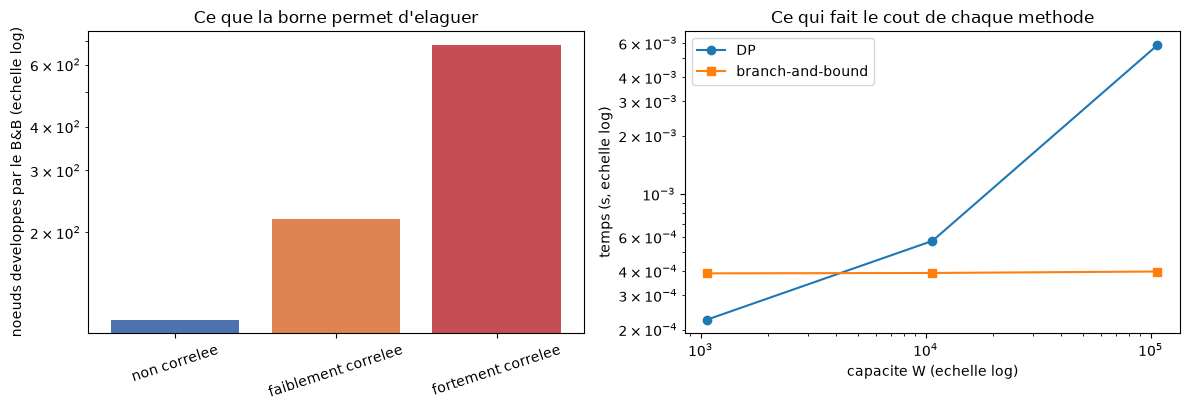

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

noms = [r[0].replace("_", " ") for r in resultats_famille]
noeuds = [r[4] for r in resultats_famille]
axes[0].bar(noms, noeuds, color=["#4C72B0", "#DD8452", "#C44E52"])
axes[0].set_yscale("log")
axes[0].set_ylabel("noeuds developpes par le B&B (echelle log)")
axes[0].set_title("Ce que la borne permet d'elaguer")
axes[0].tick_params(axis="x", rotation=18)

capacites = [r[0] for r in resultats_capacite]
temps_dp = [r[1] for r in resultats_capacite]
temps_bb = [r[2] for r in resultats_capacite]
axes[1].plot(capacites, temps_dp, "o-", label="DP")
axes[1].plot(capacites, temps_bb, "s-", label="branch-and-bound")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("capacite W (echelle log)")
axes[1].set_ylabel("temps (s, echelle log)")
axes[1].set_title("Ce qui fait le cout de chaque methode")
axes[1].legend()

fig.tight_layout()
plt.show()


### Lecture de la figure

A gauche, le nombre de nœuds passe de 113 a 682 **a taille de probleme identique** (40 objets, capacite fixee a 50 % du poids total) : seule la structure de l'instance change, et elle suffit a multiplier l'arbre par six. A droite, la DP suit la capacite (d'un facteur proche de dix par decennie, cf. 3.2) tandis que le B&B reste plat a 113 nœuds — les deux panneaux disent la meme chose par deux mesures differentes : chaque methode exacte a un axe de cout different, et choisir revient a savoir **lequel des deux axes est petit dans l'instance posee**.


## 4. Synthese : quel algorithme exact choisir

| Situation | Methode | Pourquoi |
|---|---|---|
| `W` petit (quelques milliers) | **DP** | cout `O(n*W)`, previsible, sans dependance a la structure |
| `W` grand, instances non correlees | **branch-and-bound** | la borne discrimine, l'arbre reste petit |
| `W` grand, instances fortement correlees | **MILP (HiGHS)** | la borne maison s'effondre ; le solveur ajoute coupes et heuristiques |
| besoin d'une solution vite, qualite non garantie | **glouton de ratio** | exact sur les instances faciles, mesurablement faux ailleurs |

Le point a retenir n'est pas le tableau mais son critere : **le cout d'un algorithme exact se mesure sur l'axe qu'il explore**, et cet axe depend de l'instance, pas de sa taille. Une comparaison qui ne fixe que `n` ne mesure rien.


## 5. Exercices

Trois exercices, du plus mecanique au plus ouvert. Les cellules ci-dessous s'executent sans erreur tant qu'ils ne sont pas completes.


### Exercice 1 — reconstruire la solution, pas seulement sa valeur

**Contexte.** Les trois methodes de la section 2 rendent une **valeur** optimale. En pratique on veut aussi **quels objets** emporter : la cellule 8 ne conserve que `dp[capacite]`, l'information de choix est perdue avec la ligne precedente.

**Objectif.** Ecrire `sac_a_dos_dp_solution` qui renvoie `(valeur, choix)` ou `choix` est un tableau de 0/1 de longueur `n`, puis verifier sur les instances de la cellule 10 que `sum(valeurs * choix) == valeur` et `sum(poids * choix) <= capacite`.

**Indices.**
- La table complete `(n+1, capacite+1)` est necessaire pour remonter ; la version vectorisee d'une seule ligne ne suffit pas.
- Remonter depuis `(n, capacite)` : si `DP[j][c] != DP[j-1][c]` alors l'objet `j-1` est pris.


In [10]:
# Exercice 1 — reconstruire la solution, pas seulement sa valeur
# Indice : la remontee exige la table complete (n+1, capacite+1), pas la ligne vectorisee.
# Etape 1 : remplir DP[j][c] pour j de 1 a n. Etape 2 : remonter depuis (n, capacite).
def sac_a_dos_dp_solution(poids, valeurs, capacite):
    # TODO etudiant : renvoyer (valeur_optimale, choix) avec choix un tableau 0/1 de longueur n
    return None

print("Exercice 1 a completer")


Exercice 1 a completer


### Exercice 2 — une borne plus serree change-t-elle le nombre de nœuds ?

**Contexte.** Le B&B de la cellule 7 n'a qu'une borne : la relaxation LP du reste. Une borne plus serree elague davantage — mais elle coute aussi plus cher a calculer. L'arbitrage est mesurable, il ne se suppose pas.

**Objectif.** Ecrire `sac_a_dos_bb_triee` : identique a `sac_a_dos_bb`, mais les objets sont traites dans l'ordre **des poids croissants** au lieu de l'ordre des rapports `v/w`. Relever le nombre de nœuds sur les trois familles de la cellule 14 et comparer au tableau deja obtenu. Conclure : un ordre different elague-t-il mieux ?

**Indices.**
- La borne doit rester calculee dans l'ordre des rapports, sinon elle n'est plus valide : seul l'**ordre de branchement** change.
- Mesurer les deux regimes sur les memes instances, meme graine.


In [11]:
# Exercice 2 — une borne plus serree change-t-elle le nombre de noeuds ?
# Indice : la borne reste calculee dans l'ordre des rapports ; seul l'ordre de BRANCHEMENT change.
# Etape 1 : dupliquer sac_a_dos_bb en changeant l'ordre de parcours. Etape 2 : comparer les noeuds.
def sac_a_dos_bb_triee(poids, valeurs, capacite):
    # TODO etudiant : meme B&B, objets traites par poids croissant, renvoyer (optimum, noeuds)
    return None

print("Exercice 2 a completer")


Exercice 2 a completer


### Exercice 3 — ou se situe la frontiere entre DP et B&B ?

**Contexte.** La section 3.2 montre que la DP paie la capacite et la section 3.3 que le B&B paie la structure. Les deux courbes se croisent donc quelque part — et ce point depend de la famille d'instance.

**Objectif.** Ecrire `frontiere(n, famille, capacites)` qui, pour une famille donnee, renvoie la plus petite capacite a laquelle le B&B devient **plus rapide que la DP** (temps mesures, pas theoriques). Tracer la frontiere pour les trois familles et expliquer l'ordre obtenu a partir de la section 3.3.

**Indices.**
- Reprendre la boucle de la cellule 12 en parametrant la famille.
- Comparer des temps mesures sur la meme machine, et garder en tete le bruit de mesure : la frontiere est un ordre de grandeur, pas une valeur exacte.


In [12]:
# Exercice 3 — ou se situe la frontiere entre DP et B&B ?
# Indice : reprendre la boucle de la cellule 12 en parametrant la famille d'instance.
# Etape 1 : mesurer les deux temps pour une liste de capacites. Etape 2 : rendre la premiere capacite ou BB < DP.
def frontiere(n, famille, capacites):
    # TODO etudiant : renvoyer la plus petite capacite ou le B&B devient plus rapide que la DP
    return None

print("Exercice 3 a completer")

print("Exercices a completer : 1 (reconstruire la solution), 2 (ordre de branchement), 3 (frontiere DP/BB).")


Exercice 3 a completer
Exercices a completer : 1 (reconstruire la solution), 2 (ordre de branchement), 3 (frontiere DP/BB).


## Conclusion

Trois algorithmes exacts, un meme probleme, et trois reponses differentes a la question « combien ca coute » :

- la **DP** paie la capacite, et rien d'autre — c'est la seule dont le cout est previsible a l'avance ;
- le **branch-and-bound** paie la qualite de sa borne, donc la structure de l'instance ;
- **HiGHS** paie les deux mais compense par des coupes et des heuristiques, ce qui en fait le choix par defaut quand aucune structure n'est exploitable.

Ce qui a ete mesure ici, et qui ne l'etait pas dans la serie : le nombre de nœuds developpes par un B&B maison est multiplie par six **a taille de probleme constante**, alors que l'ecart de borne, lui, *diminue* d'un facteur trois sur les memes instances. La qualite de la borne en valeur et son pouvoir d'elagage sont deux grandeurs distinctes, et c'est la seconde qui fixe le cout.

**Suite** : `Search-09-LinearProgramming` pour la formulation et l'appel a un solveur ; `Search-11d-Descente-Sous-Budget` pour la borne LP utilisee comme barriere d'un voisinage ; `Search-03b-PatternDatabases` pour la meme notion de borne admissible, mais en recherche dans un graphe d'etats.
